## Interval Analysis

In [18]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [19]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [20]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [21]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

def interval_linear(lower, upper, layer):
    center = (lower + upper) / 2
    radius = (upper - lower) / 2
    new_center = center @ layer.weight.T + layer.bias
    new_radius = radius @ layer.weight.abs().T
    return new_center - new_radius, new_center + new_radius


def interval_relu(lower, upper):
    return torch.relu(lower), torch.relu(upper)


def interval_forward(model, images, labels, eps):
    lower = (images - eps).clamp(0, 1)
    upper = (images + eps).clamp(0, 1)
    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081
    lower = lower.view(-1, 784)
    upper = upper.view(-1, 784)
    lower, upper = interval_linear(lower, upper, model[1].fc)
    lower, upper = interval_relu(lower, upper)

    layer = model[1].fc2
    weight = layer.weight[labels].unsqueeze(1) - layer.weight.unsqueeze(0)
    bias = layer.bias[labels].unsqueeze(1) - layer.bias.unsqueeze(0)

    center = (lower + upper) / 2
    radius = (upper - lower) / 2
    diff_center = torch.bmm(weight, center.unsqueeze(2)).squeeze(2) + bias
    diff_radius = torch.bmm(weight.abs(), radius.unsqueeze(2)).squeeze(2)

    return diff_center - diff_radius


def verified_accuracy(model, eps):
    model.eval()
    verified = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            lower = interval_forward(model, images, labels, eps)

            lower.scatter_(1, labels.unsqueeze(1), float('inf'))
            verified += (lower >= 0).all(dim=1).sum().item()
            total += labels.size(0)

    return 100 * verified / total


epsilons = np.arange(1, 11) / 100
accuracies = []

for eps in epsilons:
    accuracy = verified_accuracy(model, eps)
    accuracies.append(accuracy)
    print(f"Epsilon: {eps:.2f}, Verified accuracy: {accuracy:.2f}%")

Epsilon: 0.01, Verified accuracy: 70.55%
Epsilon: 0.02, Verified accuracy: 23.68%
Epsilon: 0.03, Verified accuracy: 4.56%
Epsilon: 0.04, Verified accuracy: 0.58%
Epsilon: 0.05, Verified accuracy: 0.02%
Epsilon: 0.06, Verified accuracy: 0.00%
Epsilon: 0.07, Verified accuracy: 0.00%
Epsilon: 0.08, Verified accuracy: 0.00%
Epsilon: 0.09, Verified accuracy: 0.00%
Epsilon: 0.10, Verified accuracy: 0.00%


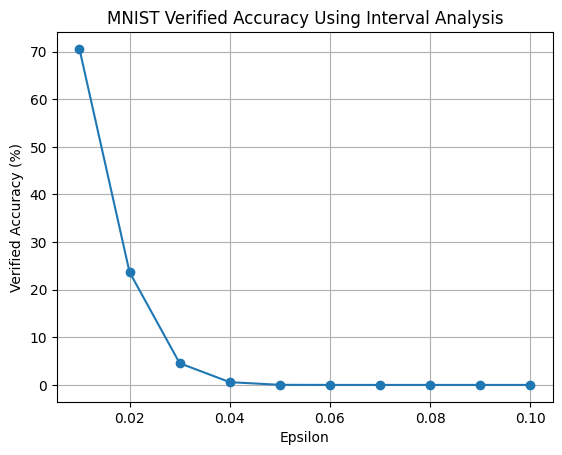

In [23]:
plt.plot(epsilons, accuracies, marker='o')
plt.xlabel("Epsilon")
plt.ylabel("Verified Accuracy (%)")
plt.title("MNIST Verified Accuracy Using Interval Analysis")
plt.grid(True)
plt.show()

Verified accuracy decreases as epsilon increases, from 70.55% at 0.01 to 0% at 0.06. This happens because larger input intervals produce wider output bounds, making robustness harder to verify. A failed verification does not necessarily mean the image is vulnerable.